# ПЗ-2. Контрастное обучение: CLIP и SigLIP

Эксперимент на CIFAR-10 и COCO Captions. Выполняйте в Google Colab по порядку. Для полного прогона рекомендуется GPU T4. Данные и веса открытые; загрузка COCO может занять продолжительное время.


In [1]:
%pip install -q transformers==4.46.3 huggingface_hub==0.26.2 scikit-learn pycocotools

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.26.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.26.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.26.2 which is incompatible.


In [2]:
import os, time, random, json, math, platform, importlib.metadata as md
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import CIFAR10
from transformers import CLIPModel, CLIPProcessor, SiglipModel, SiglipProcessor
from huggingface_hub import model_info
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device='cuda' if torch.cuda.is_available() else 'cpu'
print('Устройство:',device,'Python:',platform.python_version())
for p in ['torch','torchvision','transformers','huggingface_hub','scikit-learn']: print(p,md.version(p))
IDS=['openai/clip-vit-base-patch32','google/siglip-base-patch16-224']
REVS={x:model_info(x).sha for x in IDS}; print('Ревизии:',REVS)

Устройство: cuda Python: 3.13.16
torch 2.14.1+cu130
torchvision 0.29.1+cu130
transformers 4.46.3
huggingface_hub 0.26.2
scikit-learn 1.6.1


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Ревизии: {'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'google/siglip-base-patch16-224': '7fd15f0689c79d79e38b1c2e2e2370a7bf2761ed'}


## 1. Zero-shot на тестовой части CIFAR-10

Сравниваем два отдельных шаблона и ансамбль из пяти; для ансамбля текстовые эмбеддинги нормируются, усредняются и вновь нормируются. Используется вся тестовая выборка.

100%|██████████| 170M/170M [12:27<00:00, 228kB/s] 


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (7 outputs left out)

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/409 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

,Модель,Шаблон,Accuracy
0,openai/clip-vit-base-patch32,класс,0.8735
1,openai/clip-vit-base-patch32,фото,0.8880
2,openai/clip-vit-base-patch32,ансамбль,0.8910
3,google/siglip-base-patch16-224,класс,0.9100
4,google/siglip-base-patch16-224,фото,0.9254
5,google/siglip-base-patch16-224,ансамбль,0.9235


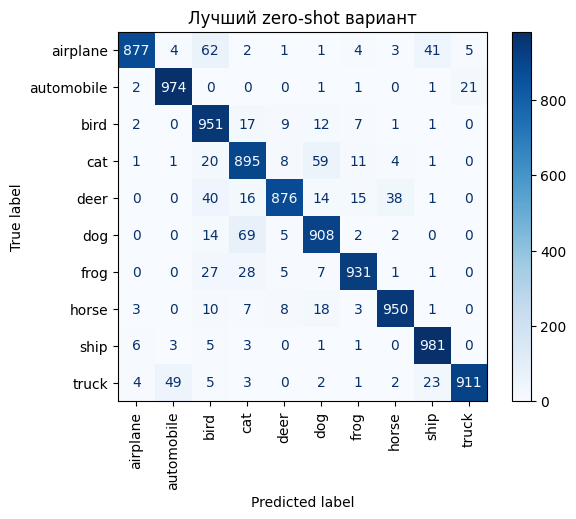

In [3]:
test=CIFAR10('./data',train=False,download=True)
classes=test.classes
templates=[['{}'],['a photo of a {}'],['a photo of a {}','a blurry photo of a {}','a photo of the {}','a small photo of a {}','a photo of one {}']]
def load_model(mid):
    if 'siglip' in mid: return SiglipModel.from_pretrained(mid,revision=REVS[mid]).to(device).eval(),SiglipProcessor.from_pretrained(mid,revision=REVS[mid])
    return CLIPModel.from_pretrained(mid,revision=REVS[mid]).to(device).eval(),CLIPProcessor.from_pretrained(mid,revision=REVS[mid])
def get_text(m,p,texts,sig):
    kw=p(text=texts,return_tensors='pt',padding='max_length' if sig else True,truncation=True).to(device)
    return F.normalize(m.get_text_features(**kw).float(),dim=-1)
def get_images(m,p,images):
    kw=p(images=images,return_tensors='pt').to(device)
    return F.normalize(m.get_image_features(**kw).float(),dim=-1)
results=[]; predictions={}; y=np.array(test.targets)
for mid in IDS:
    model,processor=load_model(mid); sig='siglip' in mid
    with torch.inference_mode():
        banks=[]
        for ts in templates:
            vec=get_text(model,processor,[t.format(c) for c in classes for t in ts],sig).reshape(10,len(ts),-1).mean(1)
            banks.append(F.normalize(vec,dim=-1))
        preds=[[] for _ in banks]
        for start in range(0,len(test),64):
            imgs=[test[i][0] for i in range(start,min(start+64,len(test)))]
            im=get_images(model,processor,imgs)
            for j,bank in enumerate(banks): preds[j].extend((im@bank.T).argmax(-1).cpu().tolist())
    for j,pred in enumerate(preds):
        acc=(np.array(pred)==y).mean(); results.append({'Модель':mid,'Шаблон':['класс','фото','ансамбль'][j],'Accuracy':acc}); predictions[(mid,j)]=pred
    del model,processor
    if device=='cuda': torch.cuda.empty_cache()
zero=pd.DataFrame(results); display(zero)
best=zero.loc[zero.Accuracy.idxmax()]; j=['класс','фото','ансамбль'].index(best['Шаблон']); pred=predictions[(best['Модель'],j)]
ConfusionMatrixDisplay(confusion_matrix(y,pred),display_labels=classes).plot(xticks_rotation=90,cmap='Blues',values_format='d'); plt.title('Лучший zero-shot вариант'); plt.show()

## 2. Функции потерь и проверки

Здесь `scale` — множитель логитов (обратная температура). При росте обычной температуры τ softmax, напротив, становится более равномерным.

In [4]:
def clip_loss(img,txt,scale):
    logits=scale*(F.normalize(img,dim=-1)@F.normalize(txt,dim=-1).T)
    target=torch.arange(len(img),device=img.device)
    return (F.cross_entropy(logits,target)+F.cross_entropy(logits.T,target))/2
def siglip_loss(img,txt,scale,bias):
    logits=scale*(F.normalize(img,dim=-1)@F.normalize(txt,dim=-1).T)+bias
    labels=2*torch.eye(len(img),device=img.device)-1
    return -F.logsigmoid(labels*logits).sum()/len(img)
assert abs(clip_loss(torch.randn(1,32),torch.randn(1,32),10).item())<1e-7
v=F.normalize(torch.randn(16,128),dim=-1)
assert clip_loss(v,v,100).item()<1e-5
print('Проверки InfoNCE пройдены; совпадающие векторы, scale=100:',clip_loss(v,v,100).item())

Проверки InfoNCE пройдены; совпадающие векторы, scale=100: 0.0


## 3. COCO Captions: признаки и разделение

Используются 6000 разных изображений train2017 и по одной подписи на изображение: 5000 для обучения, 1000 для проверки. Фиксированный seed исключает пересечение изображений. Признаки сохраняются в файле для повторного использования.

In [6]:
from urllib.request import urlretrieve
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from pycocotools.coco import COCO
from pathlib import Path
import zipfile
Path('coco').mkdir(exist_ok=True)
if not Path('coco/annotations/captions_train2017.json').exists():
    urlretrieve('http://images.cocodataset.org/annotations/annotations_trainval2017.zip','coco/annotations.zip')
    with zipfile.ZipFile('coco/annotations.zip') as z: z.extractall('coco')
coco=COCO('coco/annotations/captions_train2017.json')
ids=sorted(coco.getImgIds()); random.Random(SEED).shuffle(ids); ids=ids[:6000]
def fetch_image(i):
    meta=coco.loadImgs(i)[0]; path=Path('coco/images')/meta['file_name']; path.parent.mkdir(exist_ok=True)
    if not path.exists(): urlretrieve('http://images.cocodataset.org/train2017/'+meta['file_name'],str(path))
    caption=coco.loadAnns(coco.getAnnIds(imgIds=[i]))[0]['caption']
    return str(path),caption,i
with ThreadPoolExecutor(max_workers=12) as pool: pairs=list(pool.map(fetch_image,ids))
assert len(set(x[2] for x in pairs))==6000
cache=Path('coco/clip_features.pt')
if not cache.exists():
    model,processor=load_model(IDS[0]); iv=[]; tv=[]
    with torch.inference_mode():
        for start in range(0,len(pairs),32):
            chunk=pairs[start:start+32]; imgs=[]
            for path,_,_ in chunk:
                with Image.open(path) as im: imgs.append(im.convert('RGB'))
            iv.append(get_images(model,processor,imgs).cpu()); tv.append(get_text(model,processor,[x[1] for x in chunk],False).cpu())
    torch.save({'images':torch.cat(iv),'texts':torch.cat(tv),'ids':ids,'revision':REVS[IDS[0]]},cache)
    del model,processor
features=torch.load(cache,map_location='cpu',weights_only=True)
assert features['ids']==ids and features['revision']==REVS[IDS[0]], 'Кэш относится к другой выборке или ревизии'
I,T=features['images'],features['texts']; print('Размеры признаков:',I.shape,T.shape)

loading annotations into memory...
Done (t=0.96s)
creating index...
index created!
Размеры признаков: torch.Size([6000, 512]) torch.Size([6000, 512])


## 4. Обучение и retrieval

Одинаковые три эпохи, логируются и число шагов, и обучаемая обратная температура. Метрики считаются по отложенным 1000 парам в обоих направлениях; положительный пример — соответствующая подпись этого изображения.

,Потеря,B,Эпохи,Шаги,I→T R@1,I→T R@5,T→I R@1,T→I R@5,1/τ
0,CLIP,8,3,1875,0.233,0.557,0.267,0.598,19.949549
1,CLIP,32,3,471,0.393,0.737,0.392,0.729,13.830664
2,CLIP,128,3,120,0.433,0.759,0.431,0.749,11.193922
3,CLIP,512,3,30,0.357,0.706,0.366,0.668,10.277497
4,SigLIP,8,3,1875,0.342,0.675,0.359,0.661,16.426359
5,SigLIP,32,3,471,0.388,0.722,0.392,0.721,13.260153
6,SigLIP,128,3,120,0.369,0.716,0.379,0.695,10.669436
7,SigLIP,512,3,30,0.145,0.383,0.169,0.433,9.996844


,loss,B,epoch,steps,inverse_temperature
0,CLIP,8,1,625,14.251182
1,CLIP,8,2,1250,17.256454
2,CLIP,8,3,1875,19.949549
3,CLIP,32,1,157,11.391719
4,CLIP,32,2,314,12.627904
5,CLIP,32,3,471,13.830664
6,CLIP,128,1,40,10.376297
7,CLIP,128,2,80,10.789438
8,CLIP,128,3,120,11.193922
9,CLIP,512,1,10,10.062055


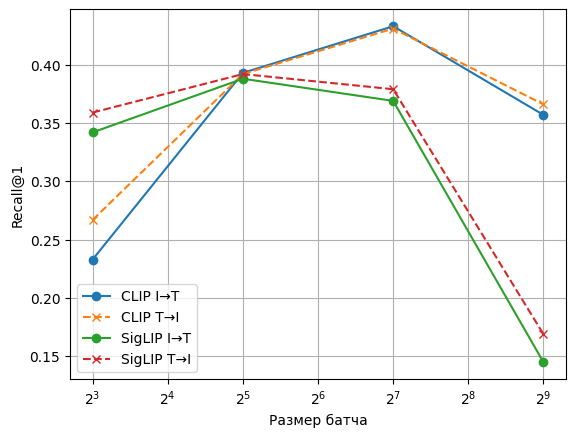

In [7]:
class Heads(nn.Module):
    def __init__(self,di,dt):
        super().__init__(); self.image=nn.Linear(di,256); self.text=nn.Linear(dt,256); self.log_scale=nn.Parameter(torch.tensor(math.log(10.))); self.bias=nn.Parameter(torch.tensor(-10.))
    def forward(self,i,t): return self.image(i),self.text(t)
def recalls(scores):
    n=len(scores); order=scores.argsort(dim=1,descending=True); truth=torch.arange(n,device=scores.device)[:,None]
    return [(order[:,:k]==truth).any(1).float().mean().item() for k in (1,5)]
rows=[]; logs=[]
for loss_name in ['CLIP','SigLIP']:
  for batch in [8,32,128,512]:
    torch.manual_seed(SEED); m=Heads(I.shape[1],T.shape[1]).to(device); opt=torch.optim.AdamW(m.parameters(),lr=1e-3)
    gen=torch.Generator().manual_seed(SEED); steps=0
    for epoch in range(3):
      order=torch.randperm(5000,generator=gen)
      for inds in order.split(batch):
        if len(inds)<2: continue
        a,b=m(I[inds].to(device),T[inds].to(device)); scale=m.log_scale.exp().clamp(max=100)
        loss=clip_loss(a,b,scale) if loss_name=='CLIP' else siglip_loss(a,b,scale,m.bias)
        opt.zero_grad(); loss.backward(); opt.step(); steps+=1
      logs.append({'loss':loss_name,'B':batch,'epoch':epoch+1,'steps':steps,'inverse_temperature':m.log_scale.exp().item()})
    with torch.inference_mode():
      a,b=m(I[5000:].to(device),T[5000:].to(device)); scores=F.normalize(a,dim=-1)@F.normalize(b,dim=-1).T
      r1,r5=recalls(scores); q1,q5=recalls(scores.T)
    rows.append({'Потеря':loss_name,'B':batch,'Эпохи':3,'Шаги':steps,'I→T R@1':r1,'I→T R@5':r5,'T→I R@1':q1,'T→I R@5':q5,'1/τ':m.log_scale.exp().item()})
retrieval=pd.DataFrame(rows); display(retrieval); display(pd.DataFrame(logs))
for name,group in retrieval.groupby('Потеря'):
    plt.plot(group.B,group['I→T R@1'],marker='o',label=name+' I→T')
    plt.plot(group.B,group['T→I R@1'],marker='x',linestyle='--',label=name+' T→I')
plt.xscale('log',base=2); plt.xlabel('Размер батча'); plt.ylabel('Recall@1'); plt.legend(); plt.grid(); plt.show()

## 5. Выводы и контрольные вопросы

На CIFAR-10 лучшая точность 92,54% получена SigLIP с шаблоном «a photo of a {класс}». Для CLIP ансамбль улучшил точность с 87,35% до 89,10%, а для SigLIP ансамбль дал 92,35%, немного ниже одного шаблона. Усреднение нескольких формулировок может уменьшать чувствительность к промпту, но улучшение не гарантировано.

Для поиска текста по изображению максимум Recall@1 составил 43,3% у CLIP при B=128; у SigLIP максимум 38,8% при B=32. При B=512 качество ниже, особенно у SigLIP (14,5%). Это сравнение не изолирует влияние B: за одинаковые три эпохи выполнено 1875 шагов при B=8 и лишь 30 при B=512. Поэтому нельзя считать падение доказательством зависимости функции потерь от больших батчей. Статья SigLIP показывает преимущество попарной сигмоидной потери и её масштабируемость; данный небольшой эксперимент с замороженными энкодерами и разным числом шагов не воспроизводит её протокол и не позволяет надёжно подтвердить или опровергнуть выводы статьи.

Обучаемый множитель 1/τ для CLIP при B=8 вырос с 10 до 19,95, следовательно температура τ снизилась примерно с 0,10 до 0,050. Для SigLIP при B=512 он остался около 10. Направление изменения зависит от числа шагов и условий обучения.

Источник: Zhai et al., Sigmoid Loss for Language Image Pre-Training, https://arxiv.org/abs/2303.15343.
